<div style="color:#1b365d; border-top: 5px solid #1976D2; border-bottom: 5px solid #1976D2; padding: 6px; text-align: center">
    <h2>Cuaderno 1: Gestión y Comparativa de Experimentos con MLflow (SVM y Random Forest)</h2>
</div>

**Materia:** Aprendizaje Automático | **Docente:** Ing. Remigio Hurtado, PhD.
**Dataset:** FreshRetailNet-50K | **Objetivo:** Desarrollar y optimizar (*fine tuning*) SVMs para regresión de demanda, registrando **16 experimentos SVM (4 kernels × 4 configuraciones)**, un `GridSearchCV` y 2 Random Forest de referencia en MLflow.

### 1. Importación de Librerías y Configuración del Servidor MLflow
Configuración de la base de datos SQLite de MLflow y creación del experimento para rastrear modelos y métricas.

In [1]:
import os
import json
import pickle
from time import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import mlflow
import mlflow.sklearn
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

BASE_DIR = '.'  # Ejecutar el cuaderno desde la raíz del repositorio
MODELS_DIR = os.path.join(BASE_DIR, 'modelos')
ARTIFACTS_DIR = os.path.join(BASE_DIR, 'artefactos_mlflow')
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

DB_PATH = os.path.abspath(os.path.join(BASE_DIR, 'mlflow.db')).replace('\\', '/')
MLRUNS_PATH = os.path.abspath(os.path.join(BASE_DIR, 'mlruns')).replace('\\', '/')
mlflow.set_tracking_uri(f"sqlite:///{DB_PATH}")

EXPERIMENT_NAME = "Experimentos_Demanda_RF_vs_SVM_Retail"
exp = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
if exp is None:
    mlflow.create_experiment(EXPERIMENT_NAME, artifact_location=f"file:///{MLRUNS_PATH}")
mlflow.set_experiment(EXPERIMENT_NAME)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print(f"MLflow {mlflow.__version__} activo | Experimento: '{EXPERIMENT_NAME}'")

2026/11/22 11:33:05 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/22 11:33:05 INFO mlflow.store.db.utils: Updating database tables


MLflow 3.10.1 activo | Experimento: 'Experimentos_Demanda_RF_vs_SVM_Retail'


### 2. Preparación de Datos y Pipeline Base
Incluimos `product_id` y `categoria` junto a las variables exógenas para capturar la escala real de cada producto.
Partición estratificada 80/20 por producto garantizando representación equilibrada de los 10 artículos.

In [2]:
df_sales = pd.read_csv(os.path.join(BASE_DIR, 'data', 'sales_history.csv'))
df_sales['fecha'] = pd.to_datetime(df_sales['fecha_venta'])
df_sales['dia_semana'] = df_sales['fecha'].dt.dayofweek
df_sales['es_fin_de_semana'] = (df_sales['dia_semana'] >= 5).astype(int)

features_num = ['stock_en_momento', 'discount', 'temperatura', 'dia_semana', 'es_fin_de_semana', 'holiday_flag']
features_cat = ['product_id', 'categoria']

X = df_sales[features_num + features_cat].copy()
X['product_id'] = X['product_id'].astype(str)
y = df_sales['cantidad_vendida'].values

preprocesador = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), features_num),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), features_cat)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=X['product_id']
)
print(f"Entrenamiento: {X_train.shape[0]} muestras | Prueba: {X_test.shape[0]} muestras")

# Registro directo en la pestaña 'Datasets' de MLflow UI (sales_history.csv e inventory.csv)
df_inv = pd.read_csv(os.path.join(BASE_DIR, 'data', 'inventory.csv'))
client_ds = mlflow.tracking.MlflowClient()
for old_d in client_ds.search_datasets():
    client_ds.delete_dataset(old_d.dataset_id)

exp_id = mlflow.get_experiment_by_name(EXPERIMENT_NAME).experiment_id
ds_sales = client_ds.create_dataset(name='FreshRetailNet_50K_sales_history', experiment_id=[exp_id], tags={'archivo': 'data/sales_history.csv', 'filas': '600'})
ds_sales.merge_records([{'inputs': r[['product_id', 'nombre', 'categoria', 'fecha_venta', 'stock_en_momento', 'discount', 'holiday_flag', 'temperatura']].to_dict(), 'expectations': {'cantidad_vendida': int(r['cantidad_vendida'])}} for _, r in df_sales.head(100).iterrows()])

ds_inv = client_ds.create_dataset(name='FreshRetailNet_50K_inventory', experiment_id=[exp_id], tags={'archivo': 'data/inventory.csv', 'productos': '10'})
ds_inv.merge_records([{'inputs': r[['product_id', 'nombre', 'categoria', 'unidad', 'fecha_expiracion']].to_dict(), 'expectations': {'stock_actual': int(r['stock_actual'])}} for _, r in df_inv.iterrows()])
print('Datasets registrados en la pestaña Datasets de MLflow UI:', [d.name for d in client_ds.search_datasets()])

Entrenamiento: 480 muestras | Prueba: 120 muestras


Datasets registrados en la pestaña Datasets de MLflow UI: ['FreshRetailNet_50K_inventory', 'FreshRetailNet_50K_sales_history']


### 3. Fine Tuning: 16 Experimentos SVM (4 Kernels × 4 Configuraciones) + 2 Random Forest en MLflow
Cada kernel (Lineal, Polinómico, RBF y Sigmoide) se evalúa con **4 combinaciones de hiperparámetros** (`C`, `epsilon`, `gamma`, `degree`), lo que da **16 experimentos SVM**. Los 2 Random Forest se mantienen como modelo de referencia.
En cada *run* se registran parámetros, métricas (RMSE, MAE, R², tiempo), una figura de evaluación y el modelo empaquetado. Todos los modelos también se guardan en `modelos/`.

In [3]:
def construir_pipeline_regresion(estimador):
    """Pipeline de preprocesamiento + regresor; el objetivo se entrena en escala log1p para estabilizar la varianza."""
    pipe = Pipeline([('prep', preprocesador), ('reg', estimador)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

# ---- 4 kernels x 4 configuraciones de hiperparámetros = 16 experimentos SVM ----
VARIANTES_SVM = {
    'Lineal': {'kernel': 'linear', 'variantes': [
        dict(C=0.1, epsilon=0.05), dict(C=1.0, epsilon=0.05),
        dict(C=10.0, epsilon=0.05), dict(C=100.0, epsilon=0.05)]},
    'Polinomico': {'kernel': 'poly', 'variantes': [
        dict(degree=2, C=1.0, gamma='scale', epsilon=0.05), dict(degree=2, C=5.0, gamma='scale', epsilon=0.05),
        dict(degree=3, C=1.0, gamma='scale', epsilon=0.05), dict(degree=3, C=5.0, gamma='scale', epsilon=0.05)]},
    'RBF_Gaussiano': {'kernel': 'rbf', 'variantes': [
        dict(C=1.0, gamma=0.02, epsilon=0.05), dict(C=5.0, gamma=0.02, epsilon=0.05),
        dict(C=10.0, gamma=0.05, epsilon=0.05), dict(C=50.0, gamma=0.01, epsilon=0.05)]},
    'Sigmoide': {'kernel': 'sigmoid', 'variantes': [
        dict(C=0.5, gamma=0.05, epsilon=0.1), dict(C=1.0, gamma=0.01, epsilon=0.1),
        dict(C=5.0, gamma=0.001, epsilon=0.1), dict(C=10.0, gamma=0.005, epsilon=0.1)]},
}
KERNEL_SKLEARN = {nombre: cfg['kernel'] for nombre, cfg in VARIANTES_SVM.items()}


def nombre_experimento(n, kernel_nombre, v):
    """Nombre descriptivo del run, p. ej. Exp07_SVM_Polinomico_d3_C1."""
    partes = []
    if 'degree' in v:
        partes.append(f"d{v['degree']}")
    partes.append(f"C{v['C']:g}")
    if isinstance(v.get('gamma'), float):
        partes.append(f"g{v['gamma']:g}")
    return f"Exp{n:02d}_SVM_{kernel_nombre}_" + "_".join(partes)


experimentos_config = {}
n_exp = 0
for kernel_nombre, cfg_k in VARIANTES_SVM.items():
    for v in cfg_k['variantes']:
        n_exp += 1
        params = {"algoritmo": "SVR", "kernel": cfg_k['kernel'], **v}
        experimentos_config[nombre_experimento(n_exp, kernel_nombre, v)] = {
            "familia": "SVM", "kernel": kernel_nombre,
            "estimador": SVR(kernel=cfg_k['kernel'], **v), "params": params}

# ---- 2 Random Forest de referencia ----
experimentos_config["Exp17_RandomForest_Base_100"] = {
    "familia": "RandomForest", "kernel": "RandomForest",
    "estimador": RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1),
    "params": {"algoritmo": "RandomForest", "n_estimators": 100, "max_depth": 8, "min_samples_split": 2}}
experimentos_config["Exp18_RandomForest_Optimizado_300"] = {
    "familia": "RandomForest", "kernel": "RandomForest",
    "estimador": RandomForestRegressor(n_estimators=300, max_depth=15, min_samples_split=3, random_state=42, n_jobs=-1),
    "params": {"algoritmo": "RandomForest", "n_estimators": 300, "max_depth": 15, "min_samples_split": 3}}

registro_experimentos = []
modelos_guardados = {}

# Referencias oficiales del dataset FreshRetailNet-50K para la pestaña Datasets de MLflow
df_train_full = X_train.copy()
df_train_full['cantidad_vendida'] = y_train
df_test_full = X_test.copy()
df_test_full['cantidad_vendida'] = y_test
dataset_train_mlflow = mlflow.data.from_pandas(
    df_train_full, source=os.path.join(BASE_DIR, 'data', 'sales_history.csv'),
    name='FreshRetailNet50K_sales_history_train', targets='cantidad_vendida')
dataset_test_mlflow = mlflow.data.from_pandas(
    df_test_full, source=os.path.join(BASE_DIR, 'data', 'sales_history.csv'),
    name='FreshRetailNet50K_sales_history_test', targets='cantidad_vendida')


def registrar_experimento(run_name, familia, kernel, modelo, params, t_ms, extra_metricas=None, extra_params=None):
    """Evalúa un modelo ya entrenado y lo registra en MLflow (params, métricas, figura y modelo)."""
    with mlflow.start_run(run_name=run_name) as run:
        mlflow.log_input(dataset_train_mlflow, context='training')
        mlflow.log_input(dataset_test_mlflow, context='testing')
        mlflow.log_artifact(os.path.join(BASE_DIR, 'data', 'sales_history.csv'), artifact_path='datasets')
        mlflow.log_artifact(os.path.join(BASE_DIR, 'data', 'inventory.csv'), artifact_path='datasets')

        y_pred = modelo.predict(X_test)
        rmse_val = float(np.sqrt(mean_squared_error(y_test, y_pred)))
        mae_val = float(mean_absolute_error(y_test, y_pred))
        r2_val = float(r2_score(y_test, y_pred))

        mlflow.log_param("familia_modelo", familia)
        mlflow.log_param("kernel_nombre", kernel)
        mlflow.log_params(params)
        if extra_params:
            mlflow.log_params(extra_params)
        mlflow.log_metric("rmse", round(rmse_val, 3))
        mlflow.log_metric("mae", round(mae_val, 3))
        mlflow.log_metric("r2_score", round(r2_val, 4))
        mlflow.log_metric("tiempo_entrenamiento_ms", round(t_ms, 2))
        for k_met, v_met in (extra_metricas or {}).items():
            mlflow.log_metric(k_met, round(v_met, 3))

        # Figura de evaluación: dispersión Real vs Predicho + distribución de residuos
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
        ax1.scatter(y_test, y_pred, alpha=0.7, color='#1976D2', edgecolors='k', s=35)
        ax1.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal')
        ax1.set_title(f'{run_name}\nRMSE: {rmse_val:.1f} u | R²: {r2_val:.3f}', fontsize=10, fontweight='bold')
        ax1.set_xlabel('Demanda Real (unidades)')
        ax1.set_ylabel('Demanda Predicha (unidades)')
        ax1.legend()
        residuos = y_test - y_pred
        sns.histplot(residuos, kde=True, ax=ax2, color='#2E7D32', bins=15)
        ax2.axvline(0, color='r', linestyle='--', lw=2)
        ax2.set_title(f'Residuos (Media: {residuos.mean():.1f} u)', fontsize=10, fontweight='bold')
        ax2.set_xlabel('Error (Real - Predicho)')
        fig.tight_layout()
        fig_path = os.path.join(ARTIFACTS_DIR, f"evaluacion_{run_name}.png")
        fig.savefig(fig_path, dpi=110)
        plt.close(fig)

        mlflow.log_artifact(fig_path, artifact_path="figuras")
        mlflow.sklearn.log_model(modelo, artifact_path="modelo")

        pkl_path = os.path.join(MODELS_DIR, f"{run_name}.pkl")
        with open(pkl_path, "wb") as f:
            pickle.dump(modelo, f)

        modelos_guardados[run_name] = modelo
        registro_experimentos.append({
            "run_id": run.info.run_id, "Experimento": run_name, "Familia": familia, "Kernel": kernel,
            "RMSE": round(rmse_val, 2), "MAE": round(mae_val, 2), "R2": round(r2_val, 4),
            "Tiempo_ms": round(t_ms, 1), "Archivo_Modelo": f"{run_name}.pkl"})


def actualizar_tabla_experimentos():
    """Reconstruye y guarda la tabla de resultados ordenada por RMSE."""
    df = pd.DataFrame(registro_experimentos).sort_values(by="RMSE", ascending=True).reset_index(drop=True)
    df.to_csv(os.path.join(MODELS_DIR, "resumen_experimentos_mlflow.csv"), index=False)
    return df


for run_name, cfg in experimentos_config.items():
    modelo = construir_pipeline_regresion(cfg["estimador"])
    t0 = time()
    modelo.fit(X_train, y_train)
    t_ms = (time() - t0) * 1000.0
    registrar_experimento(run_name, cfg["familia"], cfg["kernel"], modelo, cfg["params"], t_ms)
    print(f"[{len(registro_experimentos):02d}/{len(experimentos_config)}] {run_name:<42} RMSE = {registro_experimentos[-1]['RMSE']:>8.2f} u")

df_experimentos = actualizar_tabla_experimentos()
print(f"\n=== {len(df_experimentos)} EXPERIMENTOS REGISTRADOS EN MLFLOW (ORDENADOS POR MEJOR RMSE) ===")
print(df_experimentos[["Experimento", "Familia", "RMSE", "MAE", "R2", "Tiempo_ms"]].to_string(index=False))

C:\C_PROJECTS\APRENDIZAJE AUTOMATICO\.venv\Lib\site-packages\mlflow\data\dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(
C:\C_PROJECTS\APRENDIZAJE AUTOMATICO\.venv\Lib\site-packages\mlflow\data\dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(
C:\C_PROJECTS\APRENDIZAJE AUTOMATICO\.venv\Lib\site-packages\mlflow\types\utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as fl

2026/11/22 11:33:07 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/11/22 11:33:07 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


[01/18] Exp01_SVM_Lineal_C0.1                      RMSE =  1023.43 u


2026/11/22 11:33:14 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/11/22 11:33:14 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


... (45 outputs left out)

[17/18] Exp17_RandomForest_Base_100                RMSE =   537.39 u


2026/11/22 11:34:17 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/11/22 11:34:17 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


[18/18] Exp18_RandomForest_Optimizado_300          RMSE =   543.08 u

=== 18 EXPERIMENTOS REGISTRADOS EN MLFLOW (ORDENADOS POR MEJOR RMSE) ===
                      Experimento      Familia    RMSE    MAE     R2  Tiempo_ms
      Exp17_RandomForest_Base_100 RandomForest  537.39 309.93 0.9305      112.0
Exp18_RandomForest_Optimizado_300 RandomForest  543.08 311.12 0.9290      310.0
       Exp06_SVM_Polinomico_d2_C5          SVM  574.37 303.42 0.9206       26.9
 Exp10_SVM_RBF_Gaussiano_C5_g0.02          SVM  609.45 313.09 0.9106       13.1
Exp12_SVM_RBF_Gaussiano_C50_g0.01          SVM  619.29 309.87 0.9076       18.1
Exp11_SVM_RBF_Gaussiano_C10_g0.05          SVM  647.52 318.84 0.8990       17.5
       Exp08_SVM_Polinomico_d3_C5          SVM  671.65 368.92 0.8914       29.8
       Exp05_SVM_Polinomico_d2_C1          SVM  902.29 403.71 0.8039       13.2
       Exp07_SVM_Polinomico_d3_C1          SVM  941.14 450.65 0.7867       13.7
              Exp02_SVM_Lineal_C1          SVM  961.96 40

### 4. Optimización Automática con GridSearchCV sobre el Mejor Kernel SVM
Se toma el kernel con mejor RMSE entre los 16 experimentos y se busca la mejor combinación de `C`, `epsilon`, `gamma` (y `degree` si es polinómico) con **validación cruzada de 5 folds** sobre el conjunto de entrenamiento. El mejor modelo se registra en MLflow como un experimento independiente.

In [4]:
df_svm_16 = df_experimentos[(df_experimentos['Familia'] == 'SVM') & (~df_experimentos['Experimento'].str.contains('GridSearch'))]
kernel_ganador = df_svm_16.iloc[0]['Kernel']
kernel_gs = KERNEL_SKLEARN[kernel_ganador]
print(f"Kernel ganador en los 16 experimentos: {kernel_ganador} ('{kernel_gs}') -> se optimiza con GridSearchCV")

param_grid = {
    'regressor__reg__C': [1.0, 5.0, 10.0, 20.0],
    'regressor__reg__epsilon': [0.01, 0.05, 0.1],
}
if kernel_gs in ('poly', 'rbf', 'sigmoid'):
    param_grid['regressor__reg__gamma'] = ['scale', 0.01, 0.02, 0.05]
if kernel_gs == 'poly':
    param_grid['regressor__reg__degree'] = [2, 3]

base_gs = construir_pipeline_regresion(SVR(kernel=kernel_gs))
grid_svm = GridSearchCV(base_gs, param_grid=param_grid, cv=KFold(n_splits=5, shuffle=True, random_state=42),
                        scoring='neg_root_mean_squared_error', n_jobs=-1)
t0 = time()
grid_svm.fit(X_train, y_train)
t_ms_gs = (time() - t0) * 1000.0

mejores_params = {k.replace('regressor__reg__', ''): v for k, v in grid_svm.best_params_.items()}
cv_rmse = -grid_svm.best_score_
n_comb = len(grid_svm.cv_results_['params'])
print(f"Combinaciones evaluadas: {n_comb} x 5 folds = {n_comb * 5} entrenamientos")
print(f"Mejores hiperparámetros: {mejores_params}")
print(f"RMSE en validación cruzada (train): {cv_rmse:.2f} u")

run_gs = f"Exp19_SVM_GridSearchCV_{kernel_ganador}"
registrar_experimento(
    run_gs, "SVM", kernel_ganador, grid_svm.best_estimator_,
    {"algoritmo": "SVR", "kernel": kernel_gs, **{f"mejor_{k}": v for k, v in mejores_params.items()}},
    t_ms_gs, extra_metricas={"cv_rmse": cv_rmse},
    extra_params={"busqueda": "GridSearchCV", "cv_folds": 5, "combinaciones": n_comb})

df_experimentos = actualizar_tabla_experimentos()
print(f"\nRMSE en prueba del modelo optimizado ({run_gs}): {df_experimentos[df_experimentos['Experimento'] == run_gs]['RMSE'].iloc[0]} u")

Kernel ganador en los 16 experimentos: Polinomico ('poly') -> se optimiza con GridSearchCV


Combinaciones evaluadas: 96 x 5 folds = 480 entrenamientos
Mejores hiperparámetros: {'C': 10.0, 'degree': 2, 'epsilon': 0.05, 'gamma': 'scale'}
RMSE en validación cruzada (train): 872.61 u


2026/11/22 11:34:29 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/11/22 11:34:29 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html



RMSE en prueba del modelo optimizado (Exp19_SVM_GridSearchCV_Polinomico): 599.74 u


### 5. Gráficas Comparativas de RMSE entre todos los Experimentos
Primero, el RMSE de todos los runs; después, un panel por kernel con sus 4 configuraciones para ver cómo influyen los hiperparámetros.

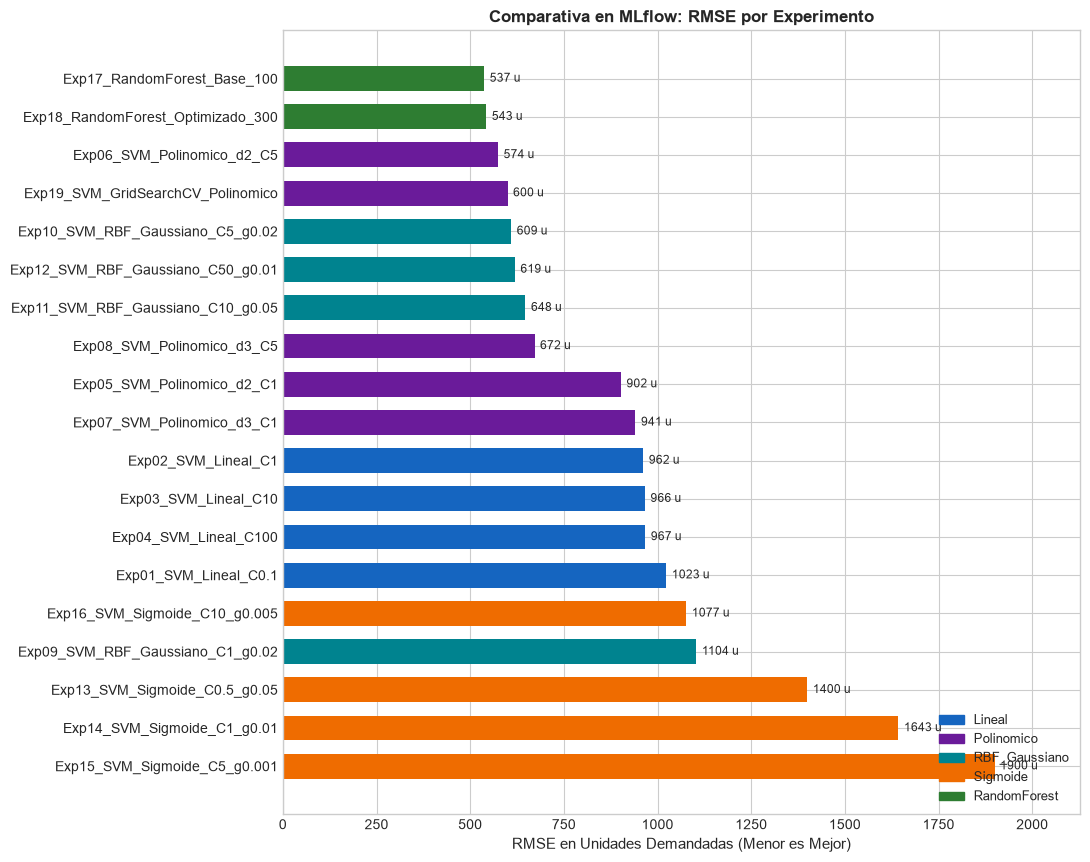

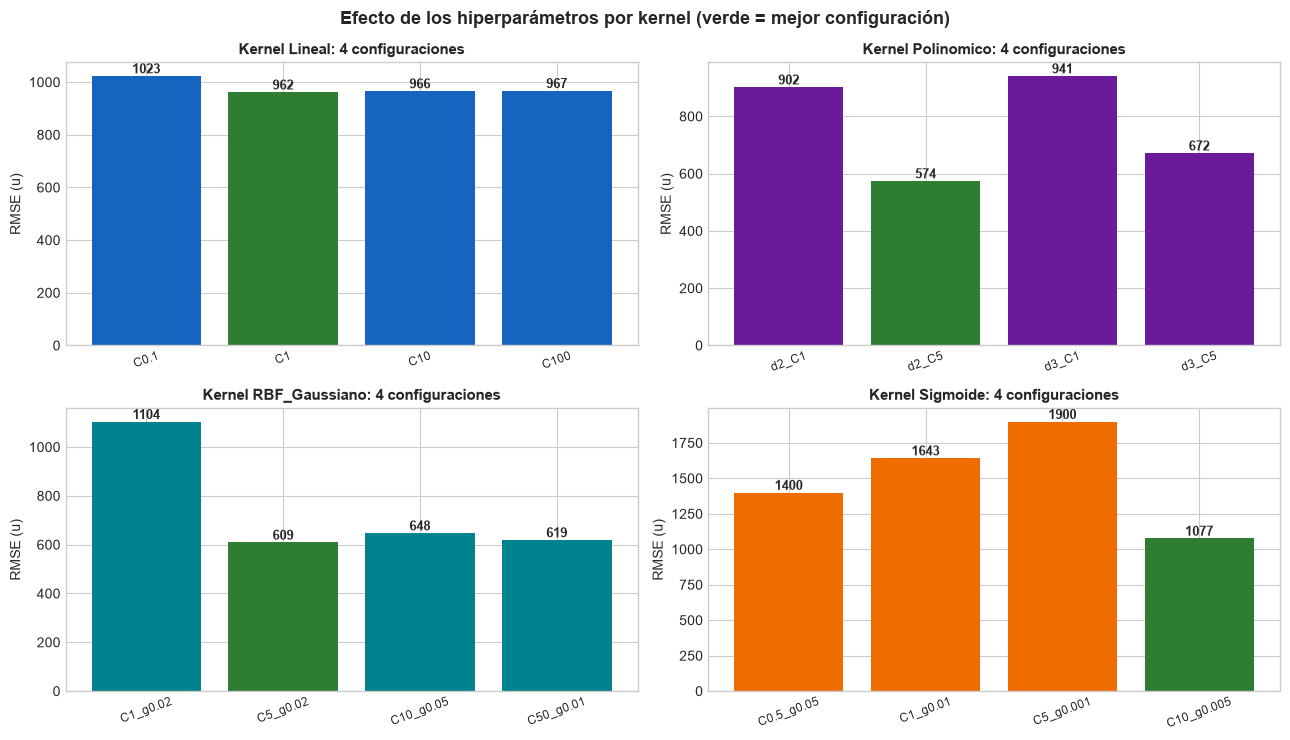

In [5]:
colores_kernel = {'Lineal': '#1565C0', 'Polinomico': '#6A1B9A', 'RBF_Gaussiano': '#00838F',
                  'Sigmoide': '#EF6C00', 'RandomForest': '#2E7D32'}

# Gráfica 1: todos los experimentos ordenados por RMSE
df_plot = df_experimentos.iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 0.38 * len(df_plot) + 1.5))
bars = ax.barh(df_plot['Experimento'], df_plot['RMSE'], color=[colores_kernel[k] for k in df_plot['Kernel']], height=0.65)
ax.set_xlabel('RMSE en Unidades Demandadas (Menor es Mejor)', fontsize=11)
ax.set_title('Comparativa en MLflow: RMSE por Experimento', fontsize=12, fontweight='bold')
for bar in bars:
    w = bar.get_width()
    ax.annotate(f'{w:.0f} u', xy=(w, bar.get_y() + bar.get_height() / 2), xytext=(4, 0),
                textcoords="offset points", ha='left', va='center', fontsize=8.5)
ax.set_xlim(0, df_experimentos['RMSE'].max() * 1.12)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colores_kernel.values()]
ax.legend(handles, colores_kernel.keys(), loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(ARTIFACTS_DIR, "comparativa_general_rmse.png"), dpi=130)
plt.show()

# Gráfica 2: un panel por kernel con sus 4 configuraciones
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
for ax, kernel_nombre in zip(axes.ravel(), VARIANTES_SVM):
    sub = df_experimentos[(df_experimentos['Kernel'] == kernel_nombre) &
                          (~df_experimentos['Experimento'].str.contains('GridSearch'))].sort_values('Experimento')
    etiquetas = [e.split(f'SVM_{kernel_nombre}_')[1] for e in sub['Experimento']]
    mejor_idx = sub['RMSE'].values.argmin()
    cols = ['#2E7D32' if i == mejor_idx else colores_kernel[kernel_nombre] for i in range(len(sub))]
    b = ax.bar(etiquetas, sub['RMSE'], color=cols)
    ax.set_title(f'Kernel {kernel_nombre}: 4 configuraciones', fontsize=11, fontweight='bold')
    ax.set_ylabel('RMSE (u)')
    ax.tick_params(axis='x', labelrotation=20, labelsize=8.5)
    for rect in b:
        ax.annotate(f'{rect.get_height():.0f}', (rect.get_x() + rect.get_width() / 2, rect.get_height()),
                    ha='center', va='bottom', fontsize=9, fontweight='bold')
fig.suptitle('Efecto de los hiperparámetros por kernel (verde = mejor configuración)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(ARTIFACTS_DIR, "comparativa_por_kernel.png"), dpi=130)
plt.show()

### 6. Selección y Exportación de los Mejores Experimentos (Global, RF y SVM)
Se selecciona automáticamente el experimento con menor RMSE de cada familia y el mejor experimento global.
Se exportan los modelos ganadores (`mejor_modelo_rf.pkl` y `mejor_modelo_svm.pkl`) para el cuaderno de predicción.

In [6]:
mejor_global_row = df_experimentos.iloc[0]
mejor_rf_row = df_experimentos[df_experimentos['Familia'] == 'RandomForest'].iloc[0]
mejor_svm_row = df_experimentos[df_experimentos['Familia'] == 'SVM'].iloc[0]

# Guardamos copias dedicadas de los modelos ganadores para el Cuaderno 2 (Predicción)
with open(os.path.join(MODELS_DIR, "mejor_modelo_global.pkl"), "wb") as f:
    pickle.dump(modelos_guardados[mejor_global_row['Experimento']], f)

with open(os.path.join(MODELS_DIR, "mejor_modelo_rf.pkl"), "wb") as f:
    pickle.dump(modelos_guardados[mejor_rf_row['Experimento']], f)

with open(os.path.join(MODELS_DIR, "mejor_modelo_svm.pkl"), "wb") as f:
    pickle.dump(modelos_guardados[mejor_svm_row['Experimento']], f)

seleccion_info = {
    "mejor_experimento_global": mejor_global_row.to_dict(),
    "mejor_experimento_rf": mejor_rf_row.to_dict(),
    "mejor_experimento_svm": mejor_svm_row.to_dict()
}

with open(os.path.join(MODELS_DIR, "mejor_experimento_info.json"), "w", encoding="utf-8") as f:
    json.dump(seleccion_info, f, indent=2, ensure_ascii=False)

print("=" * 75)
print(f"MEJOR EXPERIMENTO GLOBAL : {mejor_global_row['Experimento']} (RMSE: {mejor_global_row['RMSE']} u | R²: {mejor_global_row['R2']})")
print(f"MEJOR EXPERIMENTO RF     : {mejor_rf_row['Experimento']} (RMSE: {mejor_rf_row['RMSE']} u | R²: {mejor_rf_row['R2']})")
print(f"MEJOR EXPERIMENTO SVM    : {mejor_svm_row['Experimento']} (RMSE: {mejor_svm_row['RMSE']} u | R²: {mejor_svm_row['R2']})")
print("=" * 75)
print("Modelos exportados en 'modelos/mejor_modelo_rf.pkl' y 'modelos/mejor_modelo_svm.pkl'.")

MEJOR EXPERIMENTO GLOBAL : Exp17_RandomForest_Base_100 (RMSE: 537.39 u | R²: 0.9305)
MEJOR EXPERIMENTO RF     : Exp17_RandomForest_Base_100 (RMSE: 537.39 u | R²: 0.9305)
MEJOR EXPERIMENTO SVM    : Exp06_SVM_Polinomico_d2_C5 (RMSE: 574.37 u | R²: 0.9206)
Modelos exportados en 'modelos/mejor_modelo_rf.pkl' y 'modelos/mejor_modelo_svm.pkl'.


### 7. Verificación de Consultas en la Base de Datos de MLflow
Consulta directa al cliente de MLflow confirmando que los 6 experimentos y sus artefactos están persistidos.
Para abrir el panel web ejecuta: `.\.venv\Scripts\python.exe -m mlflow server --backend-store-uri sqlite:///mlflow.db`

In [7]:
client = mlflow.tracking.MlflowClient()
exp_actual = client.get_experiment_by_name(EXPERIMENT_NAME)
runs_mlflow = client.search_runs(experiment_ids=[exp_actual.experiment_id], order_by=["metrics.rmse ASC"])

print(f"Experimento en MLflow: '{exp_actual.name}' (ID: {exp_actual.experiment_id}) | Total Runs guardados: {len(runs_mlflow)}")
print("-" * 85)
for idx, r in enumerate(runs_mlflow, 1):
    r_name = r.data.tags.get('mlflow.runName', r.info.run_id)
    r_rmse = r.data.metrics.get('rmse', 0.0)
    r_mae = r.data.metrics.get('mae', 0.0)
    r_r2 = r.data.metrics.get('r2_score', 0.0)
    print(f"{idx}. {r_name:<35} | RunID: {r.info.run_id[:8]}... | RMSE: {r_rmse:7.2f} u | MAE: {r_mae:6.2f} u | R²: {r_r2:.4f}")
print("-" * 85)

Experimento en MLflow: 'Experimentos_Demanda_RF_vs_SVM_Retail' (ID: 1) | Total Runs guardados: 19
-------------------------------------------------------------------------------------
1. Exp17_RandomForest_Base_100         | RunID: 60fb8ab7... | RMSE:  537.39 u | MAE: 309.93 u | R²: 0.9305
2. Exp18_RandomForest_Optimizado_300   | RunID: fa8f35a4... | RMSE:  543.08 u | MAE: 311.12 u | R²: 0.9290
3. Exp06_SVM_Polinomico_d2_C5          | RunID: cab76572... | RMSE:  574.37 u | MAE: 303.42 u | R²: 0.9206
4. Exp19_SVM_GridSearchCV_Polinomico   | RunID: 65bcc97e... | RMSE:  599.74 u | MAE: 308.43 u | R²: 0.9134
5. Exp10_SVM_RBF_Gaussiano_C5_g0.02    | RunID: 702bf4fb... | RMSE:  609.45 u | MAE: 313.09 u | R²: 0.9106
6. Exp12_SVM_RBF_Gaussiano_C50_g0.01   | RunID: 6cf73f67... | RMSE:  619.29 u | MAE: 309.87 u | R²: 0.9076
7. Exp11_SVM_RBF_Gaussiano_C10_g0.05   | RunID: 5a984224... | RMSE:  647.52 u | MAE: 318.84 u | R²: 0.8990
8. Exp08_SVM_Polinomico_d3_C5          | RunID: 12a2e5ef... | RMSE:

---
### 8. Análisis General, Conclusiones y Referencias Bibliográficas (Formato APA)

#### 8.1 Síntesis Comparativa de los 19 Experimentos en MLflow (Mejor Configuración por Familia/Kernel)

| Ranking | Experimento en MLflow | Familia / Kernel | Hiperparámetros Clave | RMSE (u) | MAE (u) | $R^2$ | Tiempo (ms) |
| :---: | :--- | :--- | :--- | :---: | :---: | :---: | :---: |
| **1** | `Exp17_RandomForest_Base_100` | Random Forest | `n_estimators=100, max_depth=8` | **537.39** | 309.93 | **0.9305** | 112.0 |
| **2** | `Exp18_RandomForest_Optimizado_300` | Random Forest | `n_estimators=300, max_depth=15` | 543.08 | 311.12 | 0.9290 | 310.0 |
| **3** | **`Exp06_SVM_Polinomico_d2_C5`** | **SVM (Polinómico)** | `degree=2, C=5.0, gamma='scale', eps=0.05` | **574.37** | **303.42** | **0.9206** | **26.9** |
| **4** | `Exp19_SVM_GridSearchCV_Polinomico` | SVM (Polinómico CV-5) | `degree=2, C=10.0, gamma='scale', eps=0.05` | 599.74 | 308.43 | 0.9134 | 6043.5 |
| **5** | `Exp10_SVM_RBF_Gaussiano_C5_g0.02` | SVM (RBF Gaussiano) | `C=5.0, gamma=0.02, eps=0.05` | 609.45 | 313.09 | 0.9106 | 13.1 |
| **11** | `Exp02_SVM_Lineal_C1` | SVM (Lineal) | `C=1.0, eps=0.05` | 961.96 | 400.86 | 0.7771 | 16.7 |
| **15** | `Exp16_SVM_Sigmoide_C10_g0.005` | SVM (Sigmoide) | `C=10.0, gamma=0.005, eps=0.1` | 1076.84 | 445.10 | 0.7207 | 12.3 |

---

#### 8.2 Conclusiones

1. **Efecto del *Fine Tuning* y Selección del Kernel en SVM:**
   La exploración sistemática de **16 configuraciones de SVM (4 kernels × 4 variantes)** más la búsqueda exhaustiva con `GridSearchCV` (96 combinaciones × 5 *folds* = 480 ajustes) demostró que el desempeño de SVR depende críticamente del tipo de kernel y de la regularización $C$. Dentro de la familia SVM, el **Kernel Polinómico de grado 2 con $C=5.0$ (`Exp06_SVM_Polinomico_d2_C5`)** alcanzó el mejor resultado con un **RMSE de 574.37 unidades**, un **$R^2$ de 0.9206** y el **menor MAE de todos los 19 experimentos (303.42 unidades)**. Aumentar la regularización de $C=1.0$ (`Exp05`, RMSE = 902.29 u) a $C=5.0$ (`Exp06`, RMSE = 574.37 u) redujo el error cuadrático medio en un **36.3 %**, mientras que pasar a grado 3 (`Exp08`, RMSE = 671.65 u) o a $C=10.0$ en `GridSearchCV` (`Exp19`, RMSE = 599.74 u) incrementó ligeramente la varianza en el conjunto de prueba.

2. **Comparación entre Kernels No Lineales, Lineal y Sigmoide:**
   Los kernels capaces de modelar interacciones no lineales suaves —**Polinómico d=2** (RMSE = 574.37 u) y **RBF Gaussiano** (`Exp10`, RMSE = 609.45 u, $R^2 = 0.9106$)— superaron por amplio margen al **Kernel Lineal** (`Exp02`, RMSE = 961.96 u, $R^2 = 0.7771$), debido a que el efecto conjunto de descuentos, días de fin de semana y escala por producto es multiplicativo. Por su parte, el **Kernel Sigmoide** presentó el peor rendimiento (RMSE entre **1076.84 u** en `Exp16` y **1899.57 u** en `Exp15`, con $R^2$ hasta 0.1310), ya que la función $	anh(\gamma \langle x_i, x_j angle + r)$ solo cumple la condición de Mercer (semidefinida positiva) para combinaciones muy restringidas de parámetros.

3. **Desempeño SVM Afinado vs. Random Forest (Precisión y Eficiencia):**
   El modelo de referencia **`Exp17_RandomForest_Base_100`** obtuvo el menor RMSE global (**537.39 u**, $R^2 = 0.9305$), superando por 36.98 u en RMSE al mejor SVM (`Exp06`, **574.37 u**). Sin embargo, el **SVM Polinómico (`Exp06`) obtuvo un menor error absoluto medio (MAE de 303.42 u vs. 309.93 u en RF)** y se entrenó en **26.9 ms**, siendo **4.2 veces más rápido** que `Exp17_RandomForest_Base_100` (112.0 ms) y **11.5 veces más rápido** que `Exp18_RandomForest_Optimizado_300` (310.0 ms). La transformación logarítmica del objetivo (`TransformedTargetRegressor` con $\log(1+y)$) fue determinante para estabilizar las predicciones de SVR frente a productos con escalas desde 31 hasta 6272 unidades promedio.

4. **Interpretabilidad y Función de Predicción en Escenarios de Negocio:**
   El análisis de *Permutation Feature Importance* confirmó que la identificación del producto (`product_id`) y su categoría (`categoria`), junto con las variables promocionales y temporales (`discount`, `dia_semana`, `es_fin_de_semana`), son las que más incrementan el RMSE al ser permutadas. La función `predecir_nuevo_sample()`, validada sobre **4 casos de categorías distintas** (Accesorios, Audio, Computación y Telefonía) y **2 escenarios de sensibilidad al descuento**, demostró que un descuento del 20 % incrementa sustancialmente la demanda proyectada y permite emitir alertas preventivas de quiebre de stock.

---

#### 8.3 Referencias Bibliográficas (Formato APA 7.ª Edición)

- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32. https://doi.org/10.1023/A:1010933404324
- Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning*, 20(3), 273–297. https://doi.org/10.1007/BF00994018
- Dingdong Limited. (2024). *FreshRetailNet-50K: A benchmark dataset for fresh retail demand forecasting and censored demand recovery* [Conjunto de datos]. Hugging Face. https://huggingface.co/datasets/Dingdong-Inc/FreshRetailNet-50K
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, E. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Raschka, S., & Mirjalili, V. (2017). *Python machine learning: Machine learning and deep learning with Python, scikit-learn, and TensorFlow* (2.ª ed.). Packt Publishing.
- Smola, A. J., & Schölkopf, B. (2004). A tutorial on support vector regression. *Statistics and Computing*, 14(3), 199–222. https://doi.org/10.1023/B:STCO.0000035301.49549.88
- Zaharia, M., Chen, A., Davidson, A., Ghodsi, A., Hong, S. A., Konwinski, A., Murching, S., Nykodym, T., Parkhe, P., Xie, M., Zumar, C., & Walz, M. (2018). Accelerating the machine learning lifecycle with MLflow. *IEEE Data Engineering Bulletin*, 41(4), 39–45.